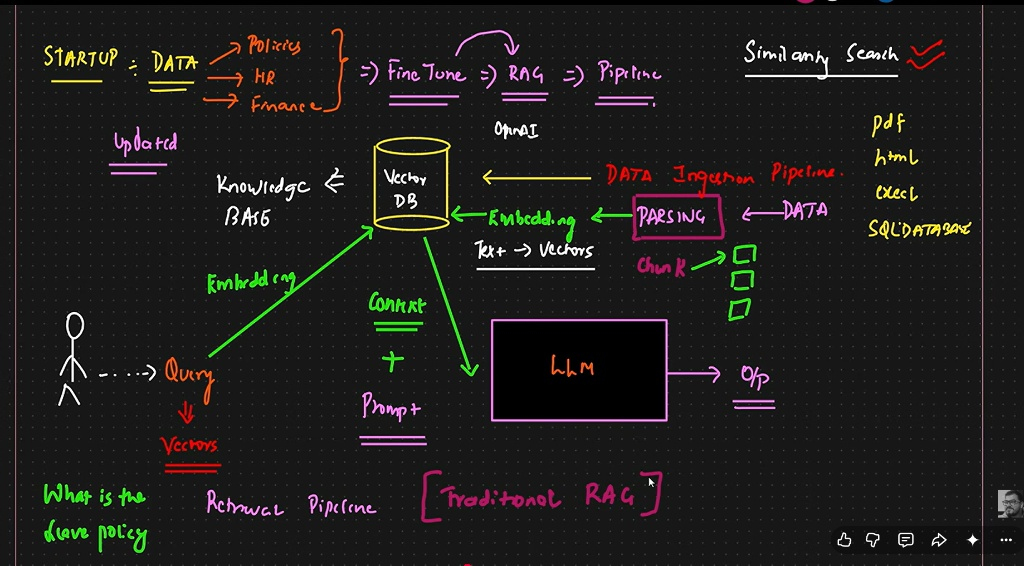


1. What Problem Does RAG Solve?Public LLMs (like Gemini, GPT, or Llama) were trained on public internet text—Wikipedia, articles, books, and public websites. 

They have zero knowledge of private files sitting on your computer or inside a company, such as startup HR policies, internal finance spreadsheets, or private PDFs.   

If you ask a normal LLM, "What is our startup's leave policy?", it either says "I don't know" or invents a fake answer.  

 To make an LLM answer questions from private documents, there are two approaches:
 
 Fine-Tuning: You retrain the LLM's internal brain on your private files. The problem is that retraining takes a lot of time and money, and every single time a company updates one rule in a PDF, you have to retrain the model all over again.
 
 RAG (Retrieval-Augmented Generation): You do not touch or retrain the LLM. Instead, you keep your documents in a separate searchable storage system (a Knowledge Base), look up only the exact relevant paragraphs when a user asks a question, and paste those paragraphs into the prompt right along with the question.

So we haave 2 different pipelines in a RAG 

1.
Pipeline 1:

 Data Ingestion Pipeline (Preparing Your Files Ahead of Time)
 This happens before any user asks a question. Its job is to take raw, messy files and organize them so they can be searched fast:   
 
 ->Data Sources: Your private information starts out in different file formats—PDFs, HTML web pages, Excel sheets, or SQL databases.  
 -> Data Parsing & Document Structure: A parser reads those raw files and extracts clean text into a standard Document format. Every Document has two parts:  
    -> Content: The actual plain text read from the page.
    -> Metadata: Extra tracking labels attached to that text, such as which file it came from, the page number, or the author.

->Chunking (Splitting into Small Pieces): An LLM has a strict limit on how much text it can read at one time (called its context size). Also, dumping a 300-page PDF into a prompt for a one-line question is slow and confusing for the model. So we cut the big document into smaller, bite-sized paragraphs called Chunks (Chunk 1, Chunk 2, Chunk 3, etc.).   
->Embedding (Converting Text into Numbers/Vectors): Computers cannot measure whether two English sentences have the same meaning just by looking at letters. An Embedding Model reads each text chunk and translates its meaning into a list of numbers called a Vector. Sentences with similar meanings produce similar lists of numbers.   
->Vector DB (Knowledge Base): All those number lists (vectors), along with their original text chunks and metadata, are stored inside a specialized database called a Vector Database.

 This becomes your updated Knowledge Base

Pipeline 2:

 Query Retrieval Pipeline (Answering a User's Question Live)
 This happens every time a user types a question, such as "What is the leave policy?": 

 -> User Query $\rightarrow$ Embedding: The user's question is passed through the exact same Embedding Model so the question also becomes a list of numbers (a vector).  

 -> Similarity Search: The Vector DB compares the question's numbers against all the stored chunk numbers. Using mathematical distance (Similarity Search), it pulls out the top 2 or 3 chunks whose meaning is closest to the user's question. 

 ->Context + Prompt $\rightarrow$ LLM: Those retrieved chunks (now called Context) are combined with the user's original question (Prompt) and sent to the LLM.   
 
 ->Final Output (O/P): Because the LLM now has the exact leave policy paragraph right in front of it inside the prompt, it reads that context and writes a clear, accurate final answer.   

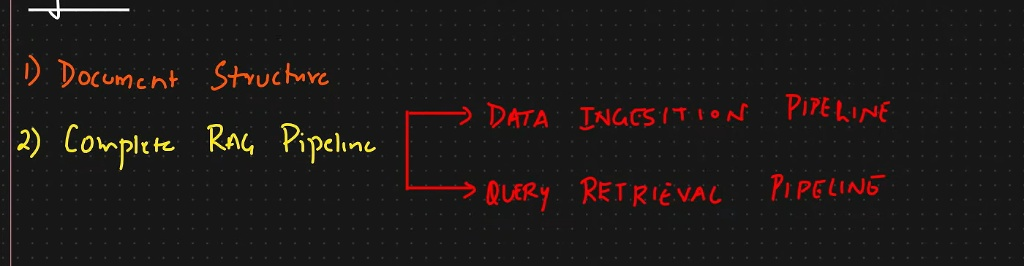

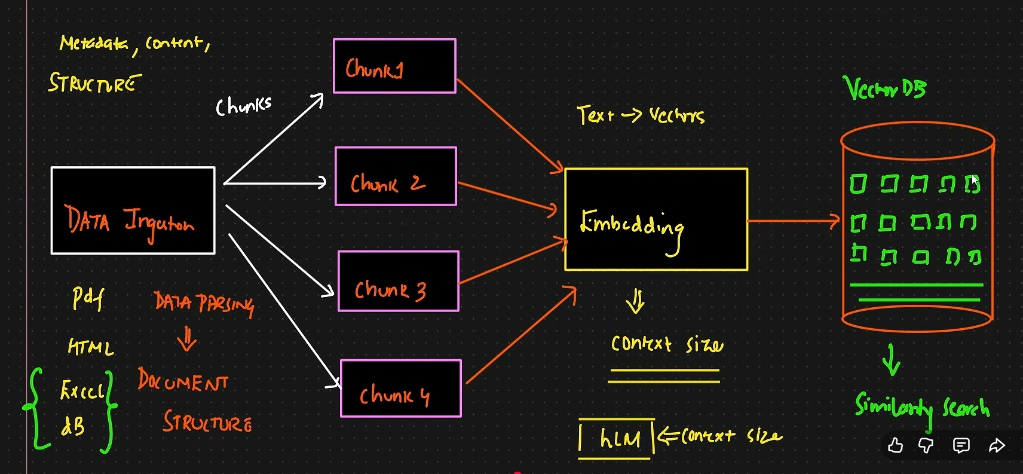

In [7]:
from langchain_core.documents import Document

doc = Document(
    page_content="This is the main text content I am using to create RAG.",
    metadata={
        "source": "example.txt",
        "pages": 1,
        "author": "Harshitha",
        "date_created": "2026-11-25"
    }
)

print(doc)
print("Content:", doc.page_content)
print("Metadata:", doc.metadata)



page_content='This is the main text content I am using to create RAG.' metadata={'source': 'example.txt', 'pages': 1, 'author': 'Harshitha', 'date_created': '2026-11-25'}
Content: This is the main text content I am using to create RAG.
Metadata: {'source': 'example.txt', 'pages': 1, 'author': 'Harshitha', 'date_created': '2026-11-25'}


In [8]:
from langchain_community.document_loaders import TextLoader

loader = TextLoader("data/speech.txt", encoding="utf-8")
text_documents = loader.load()

print(text_documents)

[Document(metadata={'source': 'data/speech.txt'}, page_content='')]


In [9]:
from langchain_community.document_loaders import PyPDFLoader

pdf_loader = PyPDFLoader("data/attention.pdf")
pdf_documents = pdf_loader.load()

print(f"Total pages loaded: {len(pdf_documents)}")
print("First page metadata:", pdf_documents[0].metadata)
print("First 300 characters of Page 1:\n", pdf_documents[0].page_content[:300])

Total pages loaded: 15
First page metadata: {'producer': 'pdfTeX-1.40.25', 'creator': 'LaTeX with hyperref', 'creationdate': '2024-04-10T21:11:43+00:00', 'author': '', 'keywords': '', 'moddate': '2024-04-10T21:11:43+00:00', 'ptex.fullbanner': 'This is pdfTeX, Version 3.141592653-2.6-1.40.25 (TeX Live 2023) kpathsea version 6.3.5', 'subject': '', 'title': '', 'trapped': '/False', 'source': 'data/attention.pdf', 'total_pages': 15, 'page': 0, 'page_label': '1'}
First 300 characters of Page 1:
 Provided proper attribution is provided, Google hereby grants permission to
reproduce the tables and figures in this paper solely for use in journalistic or
scholarly works.
Attention Is All You Need
Ashish Vaswani∗
Google Brain
avaswani@google.com
Noam Shazeer∗
Google Brain
noam@google.com
Niki Par


In [10]:
from langchain_community.document_loaders import PyMuPDFLoader

mupdf_loader = PyMuPDFLoader("data/attention.pdf")
mupdf_documents = mupdf_loader.load()

print(f"Total pages loaded: {len(mupdf_documents)}")
print("Metadata keys:", mupdf_documents[0].metadata)

Total pages loaded: 15
Metadata keys: {'producer': 'pdfTeX-1.40.25', 'creator': 'LaTeX with hyperref', 'creationdate': '2024-04-10T21:11:43+00:00', 'source': 'data/attention.pdf', 'file_path': 'data/attention.pdf', 'total_pages': 15, 'format': 'PDF 1.5', 'title': '', 'author': '', 'subject': '', 'keywords': '', 'moddate': '2024-04-10T21:11:43+00:00', 'trapped': '', 'modDate': 'D:20240410211143Z', 'creationDate': 'D:20240410211143Z', 'page': 0}


In [11]:
from langchain_community.document_loaders import DirectoryLoader, PyPDFLoader

dir_loader = DirectoryLoader(
    "data/",
    glob="**/*.pdf",
    loader_cls=PyPDFLoader,
    show_progress=True
)

all_pdf_docs = dir_loader.load()
print(f"Total pages loaded from all PDFs in data/: {len(all_pdf_docs)}")

100%|██████████| 1/1 [00:01<00:00,  1.13s/it]

Total pages loaded from all PDFs in data/: 15


In [12]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200
)

chunks = text_splitter.split_documents(pdf_documents)

print(f"Original pages: {len(pdf_documents)}")
print(f"Total chunks after splitting: {len(chunks)}")
print("\nSample Chunk 1:\n", chunks[0].page_content)
print("\nChunk 1 Metadata:", chunks[0].metadata)

Original pages: 15
Total chunks after splitting: 52

Sample Chunk 1:
 Provided proper attribution is provided, Google hereby grants permission to
reproduce the tables and figures in this paper solely for use in journalistic or
scholarly works.
Attention Is All You Need
Ashish Vaswani∗
Google Brain
avaswani@google.com
Noam Shazeer∗
Google Brain
noam@google.com
Niki Parmar∗
Google Research
nikip@google.com
Jakob Uszkoreit∗
Google Research
usz@google.com
Llion Jones∗
Google Research
llion@google.com
Aidan N. Gomez∗ †
University of Toronto
aidan@cs.toronto.edu
Łukasz Kaiser∗
Google Brain
lukaszkaiser@google.com
Illia Polosukhin∗ ‡
illia.polosukhin@gmail.com
Abstract
The dominant sequence transduction models are based on complex recurrent or
convolutional neural networks that include an encoder and a decoder. The best
performing models also connect the encoder and decoder through an attention
mechanism. We propose a new simple network architecture, the Transformer,
based solely on attention

## Data Ingestion Pipeline — Step-by-Step Summary

### Cell 1: `Document` Structure (The Standard Building Block)
* Every file loaded into LangChain is converted into a `Document` object with two parts:
  * **`page_content`**: The actual plain text read from the file.
  * **`metadata`**: Extra details about the text (filename, page number, author, date) so we can trace where every answer came from.

---

### Cell 2: `TextLoader` (Reading a `.txt` File)
* Opens `data/speech.txt` and reads all the text inside it.
* Returns a Python list containing **1 `Document` object** for the entire text file.
* `encoding="utf-8"` prevents Windows character decoding errors on special symbols or quotes.

---

### Cell 3: `PyPDFLoader` (Reading a `.pdf` File Page-by-Page)
* Opens `data/attention.pdf` and extracts text **one page at a time**.
* If a PDF has 15 pages, `.load()` returns a list of **15 separate `Document` objects** (`pdf_documents[0]` is Page 1, `pdf_documents[1]` is Page 2, etc.).
* Automatically saves the file path and page number inside each page's `metadata`.

---

### Cell 4: `PyMuPDFLoader` (Faster PDF Parsing + Extra Metadata)
* Performs the same page-by-page PDF extraction as `PyPDFLoader`, but runs much faster on large PDFs.
* Extracts richer `metadata` (document title, author, total page count, and creation date).

---

### Cell 5: `DirectoryLoader` (Loading an Entire Folder at Once)
* Scans the `data/` folder using `glob="**/*.pdf"` to automatically find every PDF inside it.
* Runs `PyPDFLoader` on every matching file and combines all extracted pages into one single list of `Document` objects—saving us from writing separate loader code for dozens of files.

---

### Cell 6: `RecursiveCharacterTextSplitter` (Chunking)
* Splits large `Document` pages into smaller, bite-sized pieces (**Chunks**) so they fit inside an LLM's context limit and improve search accuracy.
* **`chunk_size=1000`**: Keeps each chunk at or below 1,000 characters, splitting cleanly at paragraphs, line breaks, and spaces instead of cutting words in half.
* **`chunk_overlap=200`**: Repeats the last 200 characters of one chunk at the start of the next chunk so sentences and context do not get cut off between splits.
* Automatically preserves the original `metadata` on every newly created chunk.